In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [59]:
df = pd.read_csv("airbnb_data.csv")

C:\Users\adelm\AppData\Local\Temp\ipykernel_19128\1490544642.py:1: DtypeWarning: Columns (0: license) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("airbnb_data.csv")


In [11]:
df.head(5)

,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,$74,30.0,270.0,7/5/2019,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,$41,10.0,9.0,11/19/2018,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN


In [7]:
df.columns


Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license'],
      dtype='str')

In [9]:
#check for number of missing values:
print(df.isnull().sum())

id                                     0
NAME                                 250
host id                                0
host_identity_verified               289
host name                            406
neighbourhood group                   29
neighbourhood                         16
lat                                    8
long                                   8
country                              532
country code                         131
instant_bookable                     105
cancellation_policy                   76
room type                              0
Construction year                    214
price                                247
service fee                          273
minimum nights                       409
number of reviews                    183
last review                        15893
reviews per month                  15879
review rate number                   326
calculated host listings count       319
availability 365                     448
house_rules     

In [10]:
df.dtypes

id                                  int64
NAME                                  str
host id                             int64
host_identity_verified                str
host name                             str
neighbourhood group                   str
neighbourhood                         str
lat                               float64
long                              float64
country                               str
country code                          str
instant_bookable                   object
cancellation_policy                   str
room type                             str
Construction year                 float64
price                                 str
service fee                           str
minimum nights                    float64
number of reviews                 float64
last review                           str
reviews per month                 float64
review rate number                float64
calculated host listings count    float64
availability 365                  

In [60]:
#convert last review from str to datetime:
df['last review']= pd.to_datetime(df['last review'], errors='coerce')

#fill missing values:
df.fillna({'reviews per month': 0, 'last review': df['last review'].min()}, inplace=True)

# Drop records with missing 'name' or 'host name'
df.dropna(subset=['NAME', 'host name'], inplace=True)

In [61]:
#price and servie fee should be converted from str to float:
df['price'] = df['price'].replace('[\$,]', '', regex=True).astype(float)
df['service fee'] = df['service fee'].replace('[\$,]', '', regex=True).astype(float)

In [62]:
#remove duplicates: 
df.drop_duplicates(inplace=True)

In [63]:
df = df.rename(columns={'NAME': 'name'})

In [21]:
df.info()

<class 'pandas.DataFrame'>
Index: 101410 entries, 0 to 102057
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   id                              101410 non-null  int64         
 1   name                            101410 non-null  str           
 2   host id                         101410 non-null  int64         
 3   host_identity_verified          101134 non-null  str           
 4   host name                       101410 non-null  str           
 5   neighbourhood group             101384 non-null  str           
 6   neighbourhood                   101394 non-null  str           
 7   lat                             101402 non-null  float64       
 8   long                            101402 non-null  float64       
 9   country                         100884 non-null  str           
 10  country code                    101288 non-null  str           
 11  ins

In [64]:
#analyze data:
#find the top 10 neighbourhoods rented in:
most_pop_nei= df['neighbourhood'].value_counts()
most_pop_nei.head(10)

neighbourhood
Bedford-Stuyvesant    7847
Williamsburg          7678
Harlem                5395
Bushwick              4928
Hell's Kitchen        3922
Upper West Side       3807
Upper East Side       3639
East Village          3457
Midtown               3346
Crown Heights         3226
Name: count, dtype: int64

In [65]:
#most common room type:
most_room_type = df['room type'].value_counts()
most_room_type

room type
Entire home/apt    53132
Private room       45967
Shared room         2196
Hotel room           115
Name: count, dtype: int64

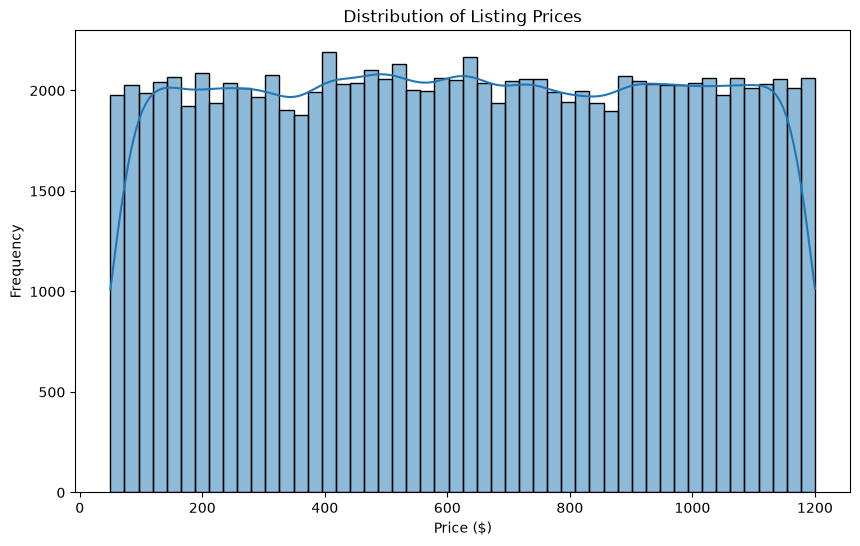

In [66]:
#Distribution of prices: 
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Distribution of Listing Prices')
plt.xlabel('Price ($)')
plt.ylabel('Frequency')
plt.show()
#prices are similar to each other

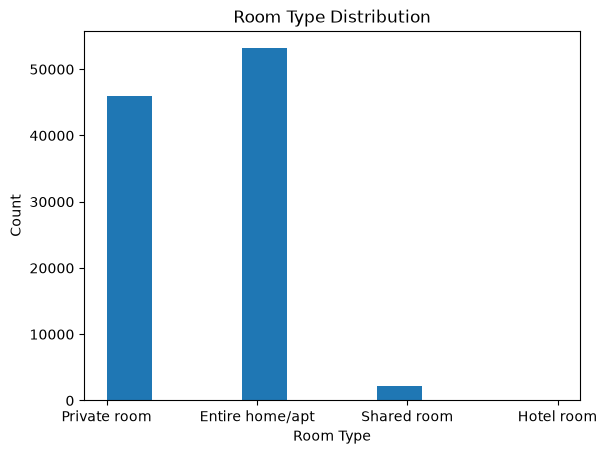

In [67]:
#Analyze distribution of Room Types:
df['room type'].hist(grid=False)
plt.title("Room Type Distribution")
plt.xlabel("Room Type")
plt.ylabel("Count")
plt.show()

Text(0, 0.5, 'Price ($)')

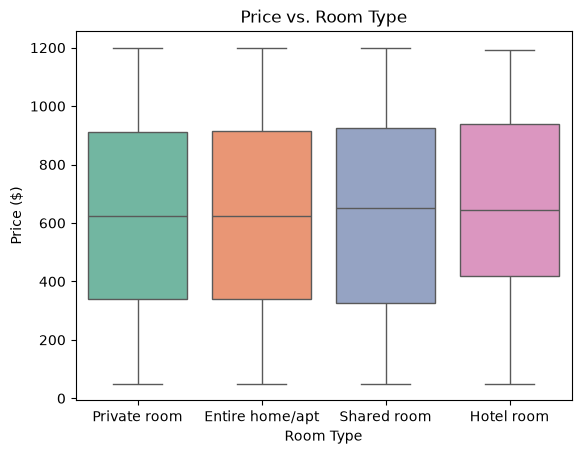

In [68]:
#price vs room type
sns.boxplot(data=df, x='room type', y='price',hue='room type', palette='Set2')
plt.title('Price vs. Room Type')
plt.xlabel('Room Type')
plt.ylabel('Price ($)')

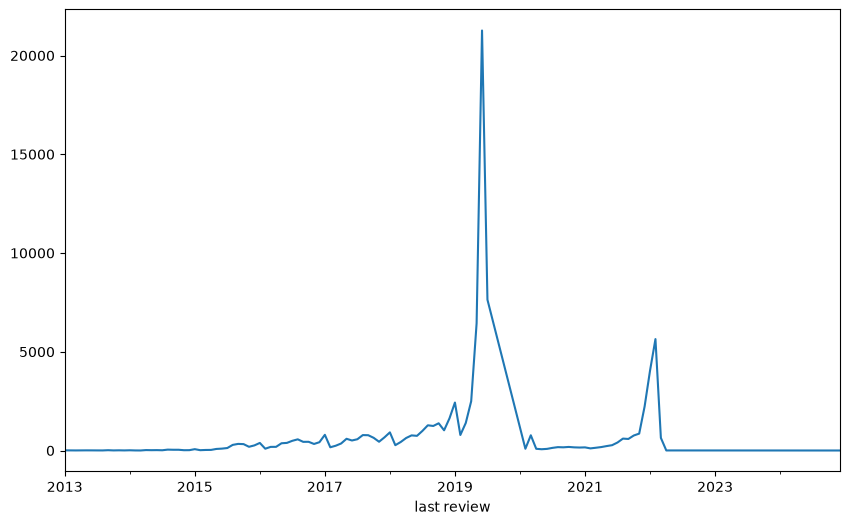

In [77]:
#plot number of reviews over time:
df['last review']=  pd.to_datetime(df['last review'])

reviews_over_time = df.groupby(df['last review'].dt.to_period('M')).size()

plt.figure(figsize=(10, 6))
reviews_over_time.plot(kind='line')
plt.xlim(pd.Period('2013-01', 'M'), pd.Period('2024-12', 'M'))
plt.show()